# KNN (K-nearest Neighbor) classifier 

## 1. Import required libraries

In [7]:
import numpy as np
from sklearn.neighbors import KNeighborsClassifier
import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns

%matplotlib inline

## 2. Get the Data (KNN_Data)

In [3]:
data = pd.read_csv("KNN_Data.csv")

## 3. Check the head of the dataframe.

In [5]:
data.head()

,XVPM,GWYH,TRAT,TLLZ,IGGA,HYKR,EDFS,GUUB,MGJM,JHZC,TARGET CLASS
0,1636.670614,817.988525,2565.995189,358.347163,550.417491,1618.870897,2147.641254,330.727893,1494.878631,845.136088,0
1,1013.402760,577.587332,2644.141273,280.428203,1161.873391,2084.107872,853.404981,447.157619,1193.032521,861.081809,1
2,1300.035501,820.518697,2025.854469,525.562292,922.206261,2552.355407,818.676686,845.491492,1968.367513,1647.186291,1
3,1059.347542,1066.866418,612.000041,480.827789,419.467495,685.666983,852.867810,341.664784,1154.391368,1450.935357,0
4,1018.340526,1313.679056,950.622661,724.742174,843.065903,1370.554164,905.469453,658.118202,539.459350,1899.850792,0


## 4. Use seaborn on the dataframe to create a pairplot with the hue set to TARGET CLASS column.

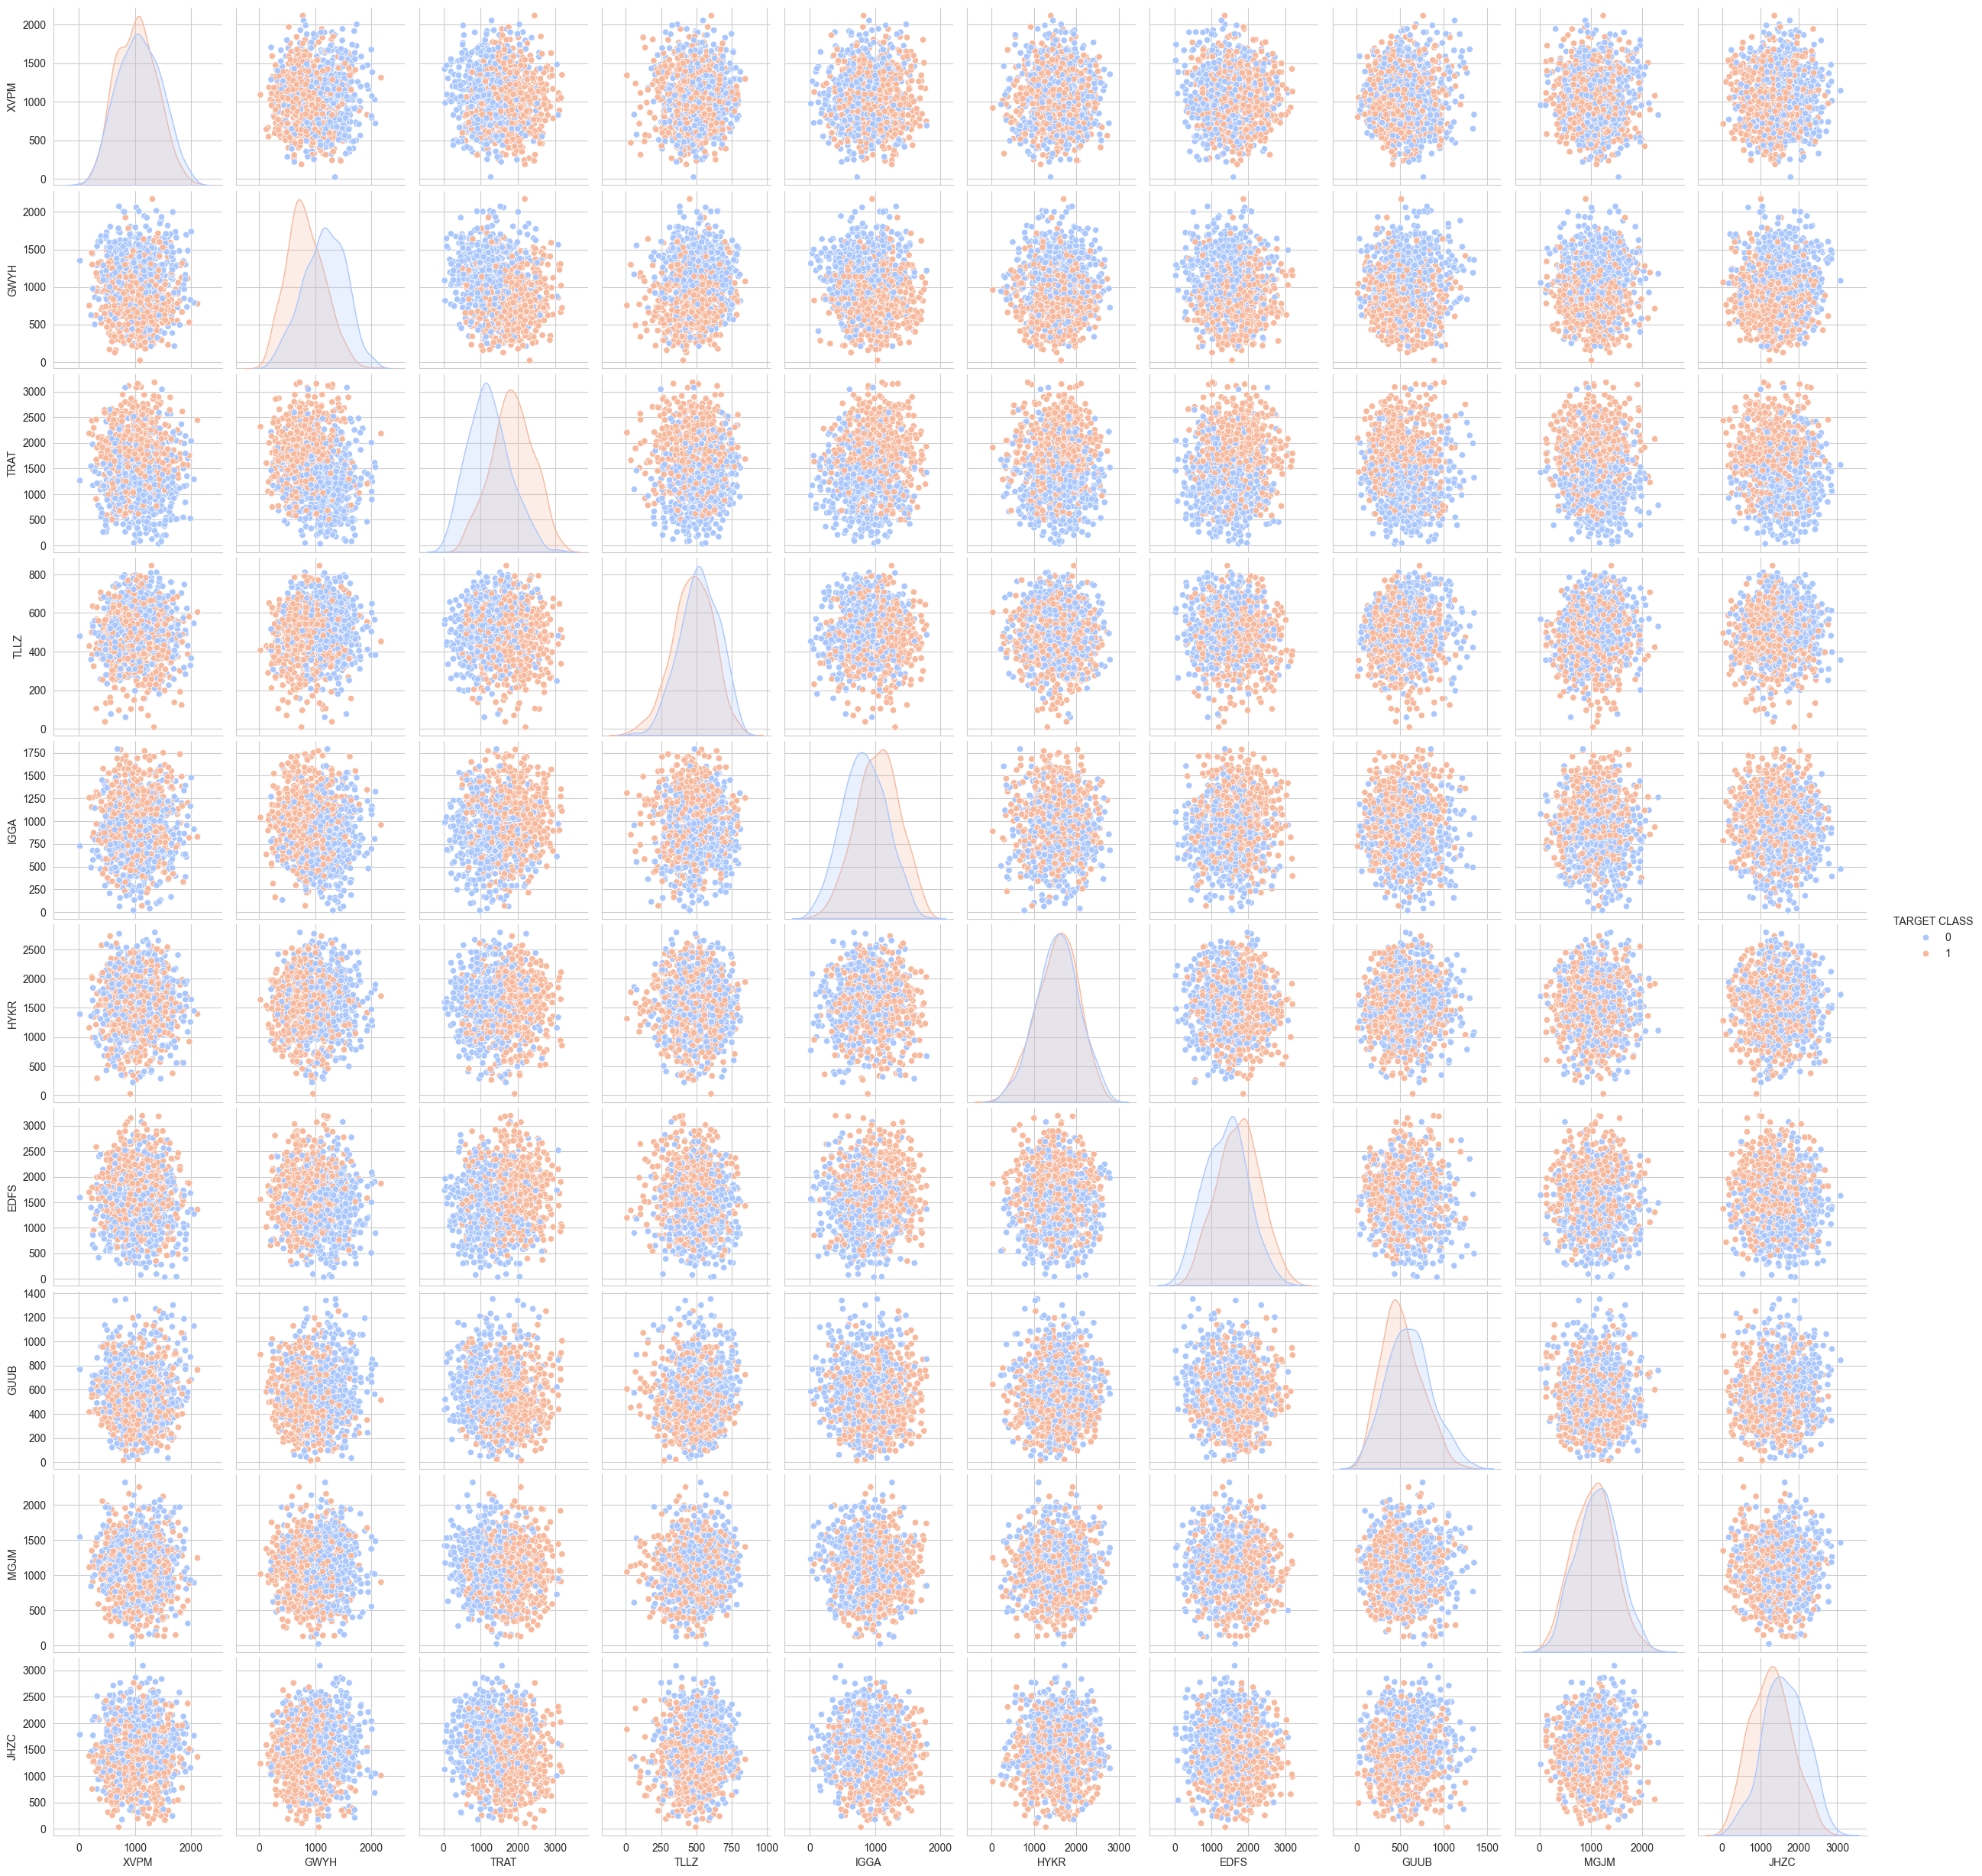

In [10]:
sns.pairplot(data, hue='TARGET CLASS', palette='coolwarm')

plt.show()

# Standardize the Variables



## 5. Import StandardScaler from Scikit learn

In [11]:
from sklearn.preprocessing import StandardScaler

### 5.1 Create a StandardScaler() object called scaler.

In [12]:
scaler = StandardScaler()

### 5.2 Fit scaler to the features.

In [16]:
X = data[['XVPM','GWYH','TRAT','TLLZ','IGGA','HYKR','EDFS','GUUB','MGJM','JHZC']]
y = data['TARGET CLASS']

scaler.fit(X)

StandardScaler()

### 5.3 Use the .transform() method to transform the features to a scaled version.

In [20]:
X_scaled = scaler.transform(X)
X_scaled

array([[ 1.56852168, -0.44343461,  1.61980773, ..., -0.93279392,
         1.00831307, -1.06962723],
       [-0.11237594, -1.05657361,  1.7419175 , ..., -0.46186435,
         0.25832069, -1.04154625],
       [ 0.66064691, -0.43698145,  0.77579285, ...,  1.14929806,
         2.1847836 ,  0.34281129],
       ...,
       [-0.35889496, -0.97901454,  0.83771499, ..., -1.51472604,
        -0.27512225,  0.86428656],
       [ 0.27507999, -0.99239881,  0.0303711 , ..., -0.03623294,
         0.43668516, -0.21245586],
       [ 0.62589594,  0.79510909,  1.12180047, ..., -1.25156478,
        -0.60352946, -0.87985868]])

### 5.4 Convert the scaled features to a dataframe and check the head of this dataframe.

In [21]:
X_scaled_df = pd.DataFrame(X_scaled, columns=X.columns)
X_scaled_df.head()

,XVPM,GWYH,TRAT,TLLZ,IGGA,HYKR,EDFS,GUUB,MGJM,JHZC
0,1.568522,-0.443435,1.619808,-0.958255,-1.128481,0.138336,0.980493,-0.932794,1.008313,-1.069627
1,-0.112376,-1.056574,1.741918,-1.504220,0.640009,1.081552,-1.182663,-0.461864,0.258321,-1.041546
2,0.660647,-0.436981,0.775793,0.213394,-0.053171,2.030872,-1.240707,1.149298,2.184784,0.342811
3,0.011533,0.191324,-1.433473,-0.100053,-1.507223,-1.753632,-1.183561,-0.888557,0.162310,-0.002793
4,-0.099059,0.820815,-0.904346,1.609015,-0.282065,-0.365099,-1.095644,0.391419,-1.365603,0.787762


# Train Test Split

## 6. Use train_test_split to split your data into a training set and a testing set.

In [22]:
from sklearn.model_selection import train_test_split

In [24]:
X_train, X_test, y_train, y_test = train_test_split(X_scaled, y, test_size=0.33, random_state=42)

# Using KNN

## 7. Import KNeighborsClassifier from scikit learn.

In [26]:
from sklearn.neighbors import KNeighborsClassifier

### 7.1 Create a KNN model instance with n_neighbors=1

In [27]:
knn = KNeighborsClassifier(n_neighbors=1)

### 7.2 Fit this KNN model to the training data.

In [28]:
knn.fit(X_train, y_train)

KNeighborsClassifier(n_neighbors=1)

# Predictions and Evaluations

## 8. Use the predict method to predict values using your KNN model and X_test.

In [31]:
y_pred = knn.predict(X_test)

### 8.1  Create a confusion matrix and classification report.

In [35]:
from sklearn.metrics import confusion_matrix, classification_report

In [33]:
confusion = confusion_matrix(y_test, y_pred)
print("Confusion Matrix:")
print(confusion)

Confusion Matrix:
[[119  44]
 [ 50 117]]


In [34]:
report = classification_report(y_test, y_pred)
print("\nClassification Report:")
print(report)


Classification Report:
              precision    recall  f1-score   support

           0       0.70      0.73      0.72       163
           1       0.73      0.70      0.71       167

    accuracy                           0.72       330
   macro avg       0.72      0.72      0.72       330
weighted avg       0.72      0.72      0.72       330



# Choosing a K Value
## 9.  Use the elbow method to pick a good K Value!

In [48]:
k_values = list(range(1, 40)) 

error_rate = []

for k in k_values:
    knn = KNeighborsClassifier(n_neighbors=k)
    knn.fit(X_train, y_train)
    y_pred = knn.predict(X_test)
    error = 1 - accuracy_score(y_test, y_pred)
    error_rate.append(error)

error_rate


[0.2848484848484848,
 0.26969696969696966,
 0.23030303030303034,
 0.23939393939393938,
 0.2212121212121212,
 0.2090909090909091,
 0.19696969696969702,
 0.19090909090909092,
 0.18181818181818177,
 0.19696969696969702,
 0.19393939393939397,
 0.19090909090909092,
 0.17878787878787883,
 0.17272727272727273,
 0.16666666666666663,
 0.17272727272727273,
 0.18181818181818177,
 0.17272727272727273,
 0.16969696969696968,
 0.17272727272727273,
 0.17575757575757578,
 0.17878787878787883,
 0.17575757575757578,
 0.17272727272727273,
 0.17575757575757578,
 0.17575757575757578,
 0.16666666666666663,
 0.16969696969696968,
 0.16666666666666663,
 0.16666666666666663,
 0.16666666666666663,
 0.16969696969696968,
 0.1636363636363637,
 0.16969696969696968,
 0.17575757575757578,
 0.18181818181818177,
 0.17878787878787883,
 0.17878787878787883,
 0.16666666666666663]

## 9.2 Now create the following plot using the error_rate

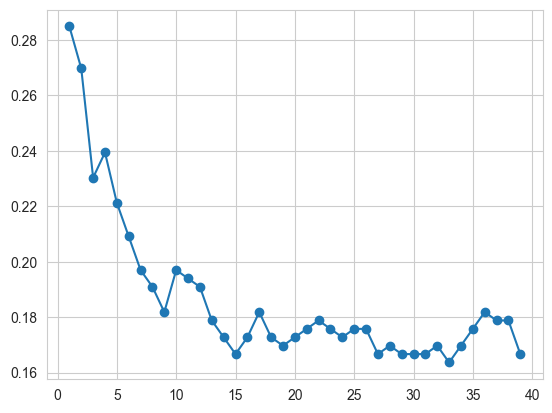

In [54]:
plt.plot(k_values, error_rate,marker='o')
plt.show()

## 10. Retrain your model with the best K value and re-do the classification report and the confusion matrix.

In [59]:

best_knn = KNeighborsClassifier(n_neighbors=15)

best_knn.fit(X_train, y_train)

y_pred_best = best_knn.predict(X_test)

classification_report_best = classification_report(y_test, y_pred_best)
print("Classification Report for the Best K Value:")
print(classification_report_best)

confusion_matrix_best = confusion_matrix(y_test, y_pred_best)
print("\nConfusion Matrix for the Best K Value:")
print(confusion_matrix_best)


Classification Report for the Best K Value:
              precision    recall  f1-score   support

           0       0.82      0.85      0.83       163
           1       0.85      0.82      0.83       167

    accuracy                           0.83       330
   macro avg       0.83      0.83      0.83       330
weighted avg       0.83      0.83      0.83       330


Confusion Matrix for the Best K Value:
[[138  25]
 [ 30 137]]


# Very Good!